# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

In [ ]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo, la carga, `info()` y la vista inicial permiten reconocer la estructura del dataset
</div>

## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- 'edad'
- 'nivel_ingreso'
- 'visitas_mes'
- 'compras_mes'
- 'gasto_publicidad_dirigida'
- 'satisfaccion'
- 'ingreso_anual'

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna 'edad' y las demas variables numericas estan correctamente representadas como valores numericos. No se identifican columnas que requieran cambios de tipo dato.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
# No se identifican columnas que requieran correccion de tipo de dato.

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
variables_numericas = [
    'edad',
    'nivel_ingreso',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'ingreso_anual'
]
df[variables_numericas].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**: Diagnóstico inicial de variables numéricas

**-'edad'** — Presenta una media de 38.26 años y un rango entre 18 y 75 años, sin valores extremos evidentes.


**-'nivel_ingreso'** — Tiene una media cercana a 30,020 y una mediana de 30,024, lo que indica una distribución bastante equilibrada.


**-'visitas_mes'** — Registra un promedio de 10 visitas mensuales, con un máximo de 25.


**-'compras_mes'** — Presenta un promedio de 1.21 compras mensuales y un máximo de 8.


**-'gasto_publicidad_dirigida'** — El 50 % central de los datos se encuentra entre 12.31 y 27.29, pero el máximo alcanza 75.51. Requiere revisar posibles valores atípicos.


**-'satisfaccion'** — Tiene una media de 3.60 sobre 5 y valores entre 1 y 5, sin anomalías evidentes.


**-'ingreso_anual'** — La media es 36.59 y la mediana 30.71. El máximo de 244.69 supera ampliamente el tercer cuartil (58.22), por lo que requiere investigar posibles valores atípicos.

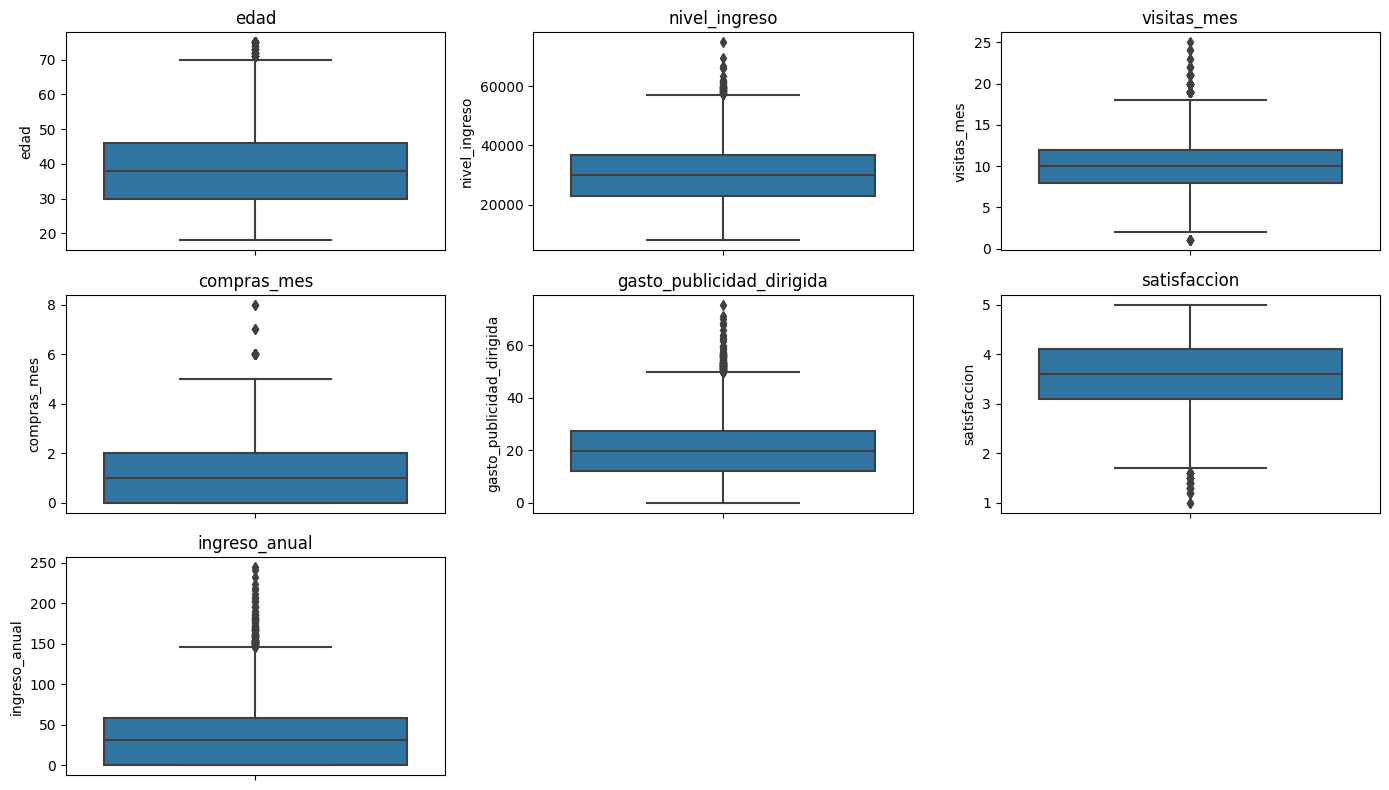

In [ ]:
# Exploracion de variables numericas con Bloxplots
plt.figure(figsize=(14, 8))

for i, variable in enumerate(variables_numericas, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[variable])
    plt.title(variable)

plt.tight_layout()
plt.show()

✍️ Comentario: Diagnóstico de valores atípicos con boxplots

**edad:** Se observan algunos valores altos, superiores a 70 años, dentro del rango válido de 18 a 75. Decisión: conservar sin ajustes.

**nivel_ingreso:** Presenta valores altos por encima de aproximadamente 57,000, con un máximo cercano a 75,000. Son valores posibles y no indican errores. Decisión: conservar sin ajustes.

**visitas_mes:** Se observan valores altos por encima de aproximadamente 18 visitas y algunos clientes con una sola visita. Estos valores son plausibles. Decisión: conservar sin ajustes.

**compras_mes:** Pocos clientes registran entre 6 y 8 compras. Son valores posibles que pueden representar clientes con alta frecuencia de compra. Decisión: conservar sin ajustes.

**gasto_publicidad_dirigida:** Presenta numerosos valores altos por encima de aproximadamente 50, con un máximo de 75.51. Podrían reflejar una mayor asignación de presupuesto a algunos clientes. Decisión: conservar los registros y realizar una prueba de sensibilidad.

**satisfaccion:** Se observan valores bajos por debajo de aproximadamente 1.7, pero todos se encuentran dentro de la escala válida de 1 a 5. Decisión: conservar sin ajustes.

**ingreso_anual:** Presenta numerosos valores altos por encima de aproximadamente 150, con un máximo de 244.69. Podrían corresponder a clientes de alto valor para la empresa. Decisión: conservar los registros y realizar una prueba de sensibilidad.

**Conclusión:** No se identifican errores evidentes en los valores atípicos, por lo que no se eliminarán registros del análisis principal. La prueba de sensibilidad permitirá comprobar si los valores extremos de gasto_publicidad_dirigida e ingreso_anual modifican las conclusiones.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
df[['miembro_premium', 'abandono']].nunique()

miembro_premium    2
abandono           2
dtype: int64

✍️ **Comentario**: Diagnóstico inicial de variables binarias

**- 'miembro_premium'** — Variable binaria correctamente codificada con dos valores posibles (0 y 1), que identifican a los clientes suscritos y no suscritos al servicio premium.

**- 'abandono'** — Variable binaria correctamente codificada con dos valores posibles (0 y 1), que identifica a los clientes que permanecen y los que abandonaron la plataforma.


#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
df[['tipo_dispositivo', 'region']].nunique()

tipo_dispositivo    3
region              4
dtype: int64

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
df['tipo_dispositivo'].value_counts()

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
df['region'].value_counts()

norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

✍️ **Comentario**: Diagnóstico inicial de variables categóricas

**- tipo_dispositivo** — Predomina el uso de dispositivos móviles, con 9.818 registros (65,45 %), mientras que las tablets representan la menor proporción, con 1.462 registros (9,75 %).


**- región**— La región Norte concentra la mayor cantidad de clientes (4.395; 29,3 %), mientras que la región Este presenta la menor cantidad (3.069; 20,46 %). La distribución entre regiones es relativamente equilibrada.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo, la distribución de dispositivo y región está cuantificada y los supuestos quedan documentados.
</div>

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
correlacion = df[variables_numericas].corr(method='pearson')
print(correlacion)

                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.009003     0.004998     0.014971   
nivel_ingreso             -0.009003       1.000000     0.001060     0.007309   
visitas_mes                0.004998       0.001060     1.000000     0.353844   
compras_mes                0.014971       0.007309     0.353844     1.000000   
gasto_publicidad_dirigida  0.000062       0.016834     0.578947     0.207528   
satisfaccion              -0.006963       0.002301    -0.003179    -0.003542   
ingreso_anual              0.017496       0.017446     0.337147     0.967149   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.000062     -0.006963   
nivel_ingreso                               0.016834      0.002301   
visitas_mes                                 0.578947     -0.003179   
compras_mes                                 0.207528     -0.003542   
gasto_pub

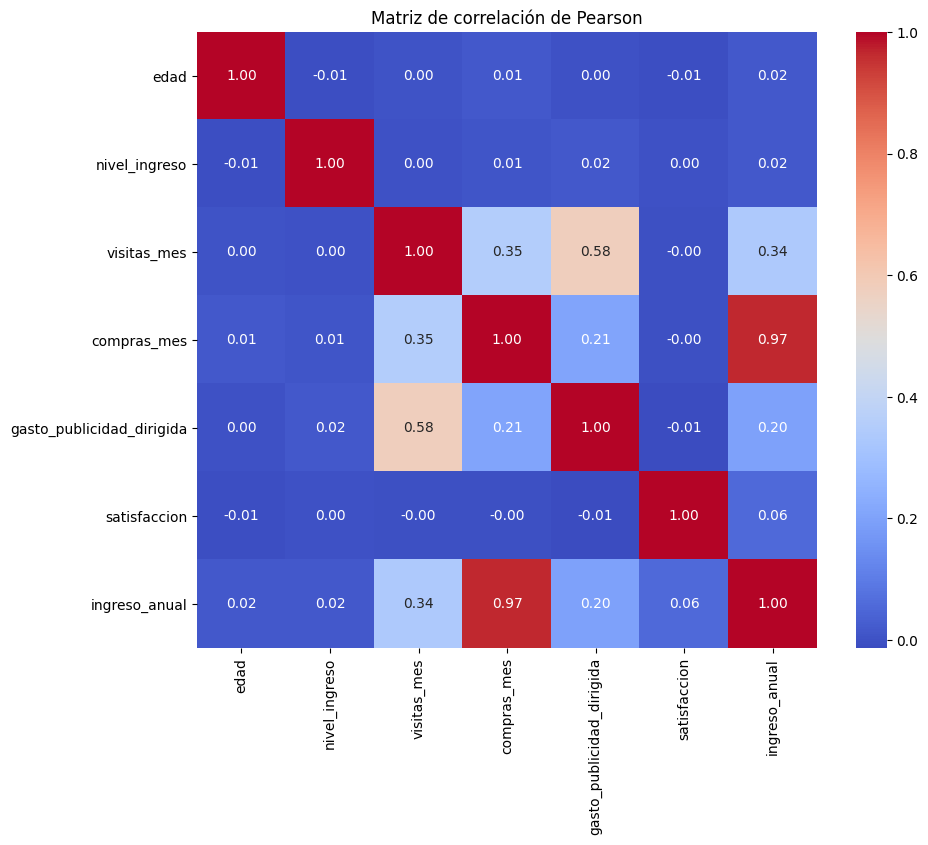

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlación de Pearson')
plt.show()

In [ ]:
# Matriz de correlación de Spearman
correlacion_spearman = df[variables_numericas].corr(method='spearman')
print(correlacion_spearman)

                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.007775     0.005205     0.015630   
nivel_ingreso             -0.007775       1.000000     0.001420     0.009004   
visitas_mes                0.005205       0.001420     1.000000     0.332943   
compras_mes                0.015630       0.009004     0.332943     1.000000   
gasto_publicidad_dirigida  0.002869       0.015393     0.559267     0.192511   
satisfaccion              -0.007590       0.005243    -0.001305    -0.002006   
ingreso_anual              0.016097       0.025017     0.320954     0.967482   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.002869     -0.007590   
nivel_ingreso                               0.015393      0.005243   
visitas_mes                                 0.559267     -0.001305   
compras_mes                                 0.192511     -0.002006   
gasto_pub

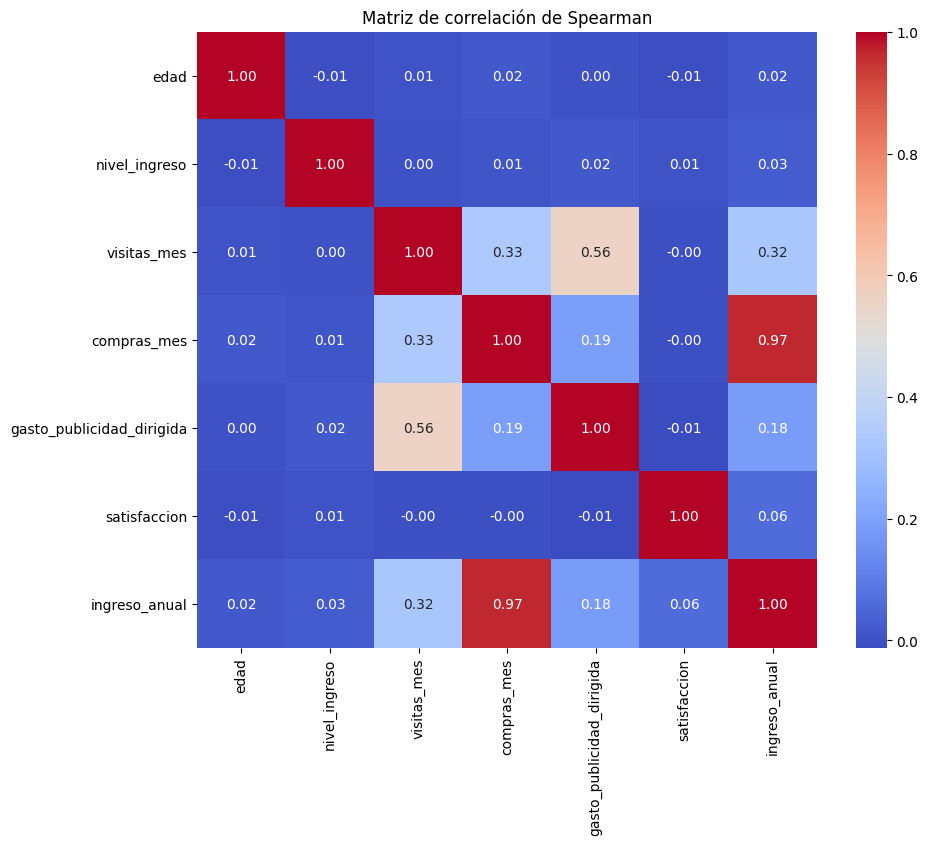

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlacion_spearman, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlación de Spearman')
plt.show()

✍️ **Comentario**:

Observaciones generales (Heatmap)  

- Se observa una correlación positiva moderada entre visitas_mes y gasto_publicidad_dirigida (Pearson: 0.58; Spearman: 0.56).

- También hay una correlación positiva débil entre visitas_mes y compras_mes (Pearson: 0.35; Spearman: 0.33).

- La mayoría de las demás variables presentan correlaciones cercanas a cero, lo que indica asociaciones muy débiles.


Los resultados de Pearson y Spearman son similares, por lo que las relaciones observadas se mantienen al evaluar tanto la asociación lineal como la monótona.

Observaciones respecto a `ingreso_anual`

- Presenta una correlación positiva extremadamente fuerte con compras_mes (Pearson: 0.97; Spearman: 0.97), lo que sugiere una posible redundancia conceptual entre ambas variables.

- Tiene una correlación positiva débil con visitas_mes (Pearson: 0.34; Spearman: 0.32).

- También presenta una correlación positiva débil con gasto_publicidad_dirigida (Pearson: 0.20; Spearman: 0.18).

- Las demás variables muestran asociaciones muy débiles con el ingreso anual.


In [ ]:
# Prueba de sensibilidad para variables gasto publicidad_dirigida e ingreso_anual
# correlaciones con y sin valores extremos
variables = ['gasto_publicidad_dirigida', 'ingreso_anual']
df_sin_outliers = df.copy()

for variable in variables:
    q1 = df[variable].quantile(0.25)
    q3 = df[variable].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    df_sin_outliers = df_sin_outliers[df_sin_outliers[variable] <= limite_superior]

pares = [
    ('gasto_publicidad_dirigida', 'visitas_mes'),
    ('gasto_publicidad_dirigida', 'compras_mes'),
    ('gasto_publicidad_dirigida', 'ingreso_anual'),
    ('visitas_mes', 'ingreso_anual')
]

resultados = []

for variable_1, variable_2 in pares:
    resultados.append({
        'relacion': f'{variable_1} vs. {variable_2}',
        'con_outliers': df[variable_1].corr(df[variable_2]),
        'sin_outliers': df_sin_outliers[variable_1].corr(df_sin_outliers[variable_2])
    })

tabla_sensibilidad = pd.DataFrame(resultados)
tabla_sensibilidad['diferencia'] = (
    tabla_sensibilidad['sin_outliers'] - tabla_sensibilidad['con_outliers']
)

print('Registros retirados:', len(df) - len(df_sin_outliers))
print(tabla_sensibilidad.round(3))

Registros retirados: 214
                                      relacion  con_outliers  sin_outliers  \
0    gasto_publicidad_dirigida vs. visitas_mes         0.579         0.564   
1    gasto_publicidad_dirigida vs. compras_mes         0.208         0.199   
2  gasto_publicidad_dirigida vs. ingreso_anual         0.197         0.191   
3                visitas_mes vs. ingreso_anual         0.337         0.330   

   diferencia  
0      -0.015  
1      -0.009  
2      -0.007  
3      -0.007  


In [ ]:
**Resultados de la prueba:** al retirar 214 registros (1.43 % del total), ninguna correlación cambió más de 0.015, y todas mantienen su dirección e interpretación. Por eso, conserva todos los datos en el análisis principal.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **No se incluye scatterplot general**:
  
  - La matriz de correlación ya nos permitio identificar las relaciones lineales entre las variables numéricas. Además, la mayoría de las correlaciones son débiles o cercanas a cero, por lo que un gráfico general con todas las variables generaría mucho ruido y podría dificultar la interpretación.

Es más útil reservar los scatterplots para analizar relaciones específicas que presenten correlaciones relevantes, especialmente las relacionadas con ingreso_anual.

### Scatterplot para pares clave

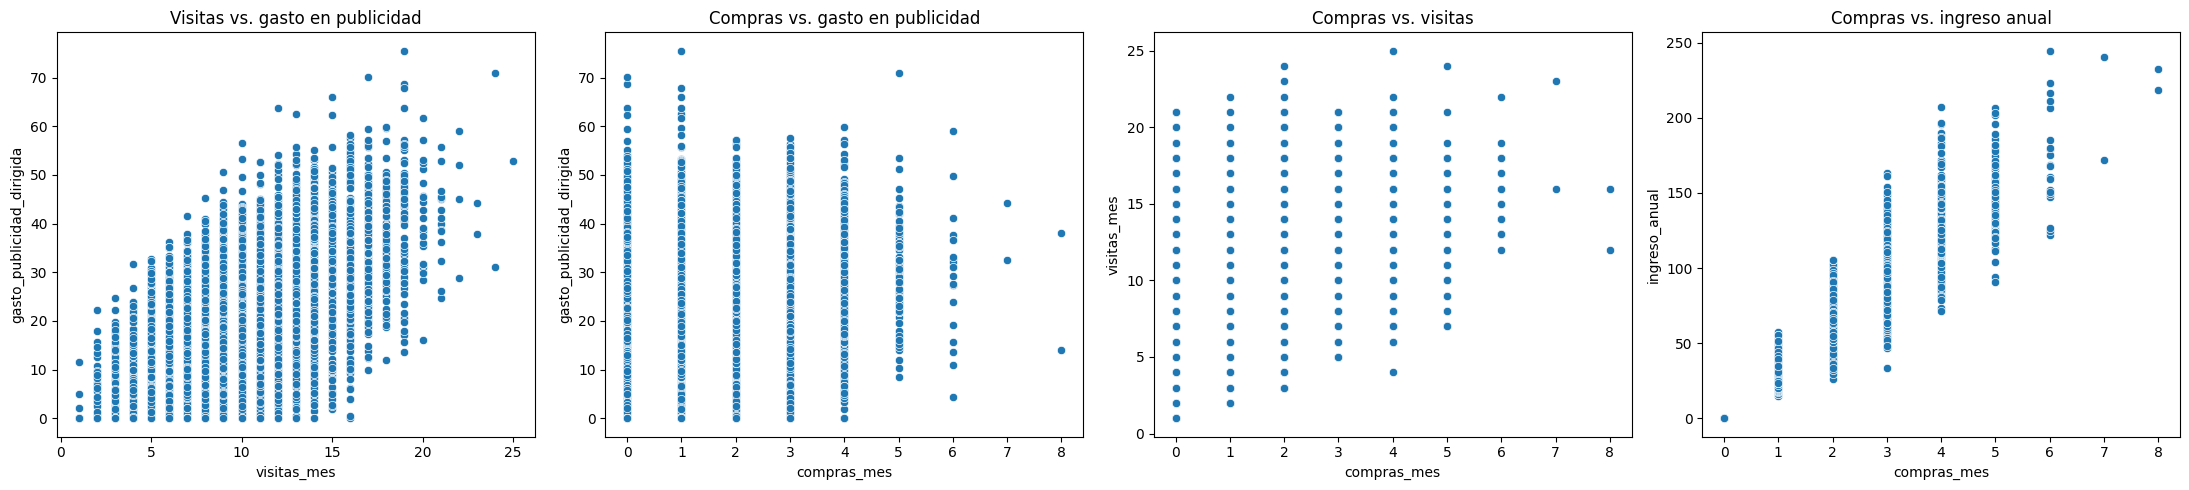

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

sns.scatterplot(data=df, x='visitas_mes', y='gasto_publicidad_dirigida', ax=axes[0])
axes[0].set_title('Visitas vs. gasto en publicidad')

sns.scatterplot(data=df, x='compras_mes', y='gasto_publicidad_dirigida', ax=axes[1])
axes[1].set_title('Compras vs. gasto en publicidad')

sns.scatterplot(data=df, x='compras_mes', y='visitas_mes', ax=axes[2])
axes[2].set_title('Compras vs. visitas')

sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual', ax=axes[3])
axes[3].set_title('Compras vs. ingreso anual')

plt.tight_layout()
plt.show()

✍️ **Comentario**:

Observaciones iniciales (Scatterplot)

**visitas_mes vs gasto_publicidad_dirigida**
* Dirección: positiva moderada.
* Dispersión: media a alta; aumenta con las visitas.
* Outliers: algunos clientes con gasto cercano a 70 o superior.
* Colinealidad: posible entre ambas variables; debe confirmarse con la matriz de correlación.

**compras_mes vs gasto_publicidad_dirigida**
* Dirección: sin relación clara.
* Dispersión: alta en casi todos los niveles de compra.
* Outliers: pocos clientes con 7 u 8 compras; también hay clientes con 0 compras y gasto cercano a 70.
* Colinealidad: no se observa.

**compras_mes vs visitas_mes**
* Dirección: positiva, de débil a moderada.
* Dispersión: alta; un mismo número de compras abarca muchos valores de visitas.
* Outliers: sin valores extremos marcados; pocos clientes con 7 u 8 compras.
* Colinealidad: posible, pero leve; debe confirmarse con la matriz de correlación.

**compras_mes vs ingreso_anual**
* Dirección: positiva fuerte; es la relación más clara.
* Dispersión: baja a media; aumenta con el número de compras.
* Outliers: sin valores claramente atípicos; pocos clientes con 7 u 8 compras.
* Colinealidad: no aplica, porque `ingreso_anual` es la variable objetivo.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo, los scatterplots son útiles, pero falta `visitas_mes` vs. `ingreso_anual`
</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes - Pearson

print('Visitas vs. gasto en publicidad:', correlacion.loc['visitas_mes', 'gasto_publicidad_dirigida'])
print('Visitas vs. compras:', correlacion.loc['visitas_mes', 'compras_mes'])
print('Compras vs. gasto en publicidad:', correlacion.loc['compras_mes', 'gasto_publicidad_dirigida'])
print('Compras vs. ingreso anual:', correlacion.loc['compras_mes', 'ingreso_anual'])

Visitas vs. gasto en publicidad: 0.5789472719412834
Visitas vs. compras: 0.353843894719897
Compras vs. gasto en publicidad: 0.20752786826577033
Compras vs. ingreso anual: 0.9671485435708576


In [ ]:
# Calcular correlación entre variables relevantes - Spearman
# No se encuentra ninguna variable que requiera análisis de correlación por el método Spearman, ya que no encontramos una relación de características monótonas y no lineales.

✍️ **Comentario**: Observaciones de correlación

**visitas_mes vs. gasto_publicidad_dirigida**
- Correlación positiva moderada (Pearson: 0.58; Spearman: 0.56).
- Sugiere que un mayor número de visitas está asociado con un mayor gasto en publicidad dirigida. No implica causalidad.

**visitas_mes vs. compras_mes**
- Correlación positiva débil (Pearson: 0.35; Spearman: 0.33).
- Las visitas presentan cierta asociación con las compras, aunque su relación es limitada.

**compras_mes vs. gasto_publicidad_dirigida**
- Correlación positiva débil (Pearson: 0.21; Spearman: 0.19).
- La asociación entre ambas variables es baja.

**compras_mes vs. ingreso_anual**
- Correlación positiva extremadamente fuerte (Pearson: 0.97; Spearman: 0.97).
- Existe una posible redundancia conceptual entre ambas variables, ya que el número de compras y el ingreso anual pueden estar estrechamente relacionados por su construcción. Se debe tener precaución al interpretar esta asociación.

**visitas_mes vs. ingreso_anual**
- Correlación positiva débil (Pearson: 0.34; Spearman: 0.32).
- El número de visitas tiene una asociación limitada con el ingreso anual.

La correlación extremadamente alta entre **compras_mes e ingreso_anual** (0.97) puede explicarse por la relación conceptual entre ambas variables: el ingreso anual representa el gasto total del cliente en la empresa durante el año, mientras que compras_mes registra su actividad de compra mensual. Por tanto, es esperable que ambas variables presenten un comportamiento muy similar.

In [ ]:
### Análisis por segmentos entre variables de interés
# Definimos grupos etarios para buscar patrones de comportamiento

df['grupo_edad'] = pd.cut(
    df['edad'],
    bins=[17, 30, 40, 50, 60, 75],
    labels=['18-30', '31-40', '41-50', '51-60', '61-75']
)

print(df['grupo_edad'].value_counts().sort_index())


18-30    3973
31-40    4770
41-50    3992
51-60    1803
61-75     462
Name: grupo_edad, dtype: int64


In [ ]:
# Calculamos la correlación entre edad e ingreso_anual
for grupo in df['grupo_edad'].unique():
    datos_grupo = df[df['grupo_edad'] == grupo]
    correlacion = datos_grupo['edad'].corr(datos_grupo['ingreso_anual'])
    print(grupo, correlacion)

41-50 -0.0010479206497169887
31-40 -0.004004487626826527
51-60 0.000473799309433835
18-30 -0.0003682987510625495
61-75 0.004139516703054374


**Interpretación:** Todos los coeficientes son cercanos a cero, dentro de cada grupo de edad, tener más o menos años no está asociado linealmente con generar mayores ingresos para la empresa.

In [ ]:
# Analizamos el ingreso anual promedio por grupo de edad para ver si encontramos algun patrón de interés
print(df.groupby('grupo_edad')['ingreso_anual'].mean())

grupo_edad
18-30    36.035424
31-40    36.113008
41-50    36.973307
51-60    37.755308
61-75    38.559848
Name: ingreso_anual, dtype: float64


**Interpretación:** Los clientes de mayor edad generan un ingreso anual promedio ligeramente superior, pero la diferencia no parece suficientemente marcada para concluir que la edad sea un factor relevante por sí solo.
También hay que resaltar que el grupo de 61-75 años tiene solo 462 clientes, frente a los casi 4.000 de los grupos más numerosos.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

corr_premium = pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
corr_abandono = pointbiserialr(df['abandono'], df['ingreso_anual'])

print('Miembro premium vs. ingreso anual:', corr_premium)
print('Abandono vs. ingreso anual:', corr_abandono)

# Correlación punto-biserial entre abandono y variables de comportamiento
variables_abandono = [
    'satisfaccion',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida'
]

for variable in variables_abandono:
    resultado = pointbiserialr(df['abandono'], df[variable])
    print(variable, '| r =', round(resultado[0], 3), '| p =', round(resultado[1], 4))

Miembro premium vs. ingreso anual: SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)
Abandono vs. ingreso anual: SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)
satisfaccion | r = -0.024 | p = 0.0035
visitas_mes | r = -0.009 | p = 0.2734
compras_mes | r = 0.008 | p = 0.3099
gasto_publicidad_dirigida | r = -0.005 | p = 0.5744


✍️ **Comentario**: Observaciones Punto-biserial

**miembro_premium vs. ingreso_anual**
- Relación positiva muy débil (r = 0.093).
- Ser miembro premium presenta una asociación positiva con el ingreso anual, aunque su magnitud es baja.
- Nota: La correlación entre membresía premium e ingreso anual es positiva, pero muy débil (r = 0.093). Dado el tamaño considerable de la muestra (15.000 clientes), esta asociación podría ser de interés para una exploración comercial posterior, aunque su magnitud actual es reducida.

**abandono vs. ingreso_anual**
- Relación negativa prácticamente nula (r = -0.003).
- No se observa una asociación relevante entre el abandono del cliente y el ingreso anual.

**abandono vs. satisfacción**
- Relación negativa prácticamente nula (r = -0.024; p = 0.0035).
- La relación es estadísticamente significativa, pero su magnitud es muy baja. Con 15.000 registros, incluso asociaciones mínimas pueden resultar significativas.

**abandono vs. visitas_mes**
- Relación prácticamente nula y no significativa (r = -0.009; p = 0.273).

**abandono vs. compras_mes**
- Relación prácticamente nula y no significativa (r = 0.008; p = 0.310).

**abandono vs. gasto_publicidad_dirigida**
- Relación prácticamente nula y no significativa (r = -0.005; p = 0.574).

En conjunto, ninguna de las variables analizadas muestra una asociación lineal relevante con el abandono.

### V de Cramér

In [ ]:
# Creación de tabla de contingencia entre variables Tipo de dispositivo y Región con valores acumulados

tabla_contingencia = pd.crosstab(df['tipo_dispositivo'], df['region'])
print(tabla_contingencia)

tabla_premium_region = pd.crosstab(df['region'], df['miembro_premium'])
print(tabla_premium_region)

region            este  norte  oeste   sur
tipo_dispositivo                          
escritorio         766   1125    935   894
móvil             2003   2843   2489  2483
tablet             300    427    386   349
miembro_premium     0    1
region                    
este             2647  422
norte            3801  594
oeste            3283  527
sur              3180  546


In [ ]:
# Función para calcular V de Cramér

from scipy.stats import chi2_contingency
import numpy as np

def calcular_v_cramer(tabla):
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    filas, columnas = tabla.shape
    v_cramer = np.sqrt(chi2 / (n * min(filas - 1, columnas - 1)))
    return v_cramer

In [ ]:
# Aplicar V de Cramér en variables relevantes

# 1. Tipo de dispositivo vs. región
chi2_1, p_1, dof_1, expected_1 = chi2_contingency(tabla_contingencia)
n_1 = tabla_contingencia.sum().sum()
cramers_v_1 = np.sqrt(chi2_1 / (n_1 * (min(tabla_contingencia.shape) - 1)))

print('Dispositivo vs. región')
print('Chi-cuadrado:', chi2_1)
print('V de Cramér:', cramers_v_1)

# 2. Región vs. miembro premium
chi2_2, p_2, dof_2, expected_2 = chi2_contingency(tabla_premium_region)
n_2 = tabla_premium_region.sum().sum()
cramers_v_2 = np.sqrt(chi2_2 / (n_2 * (min(tabla_premium_region.shape) - 1)))

print('Región vs. miembro premium')
print('Chi-cuadrado:', chi2_2)
print('V de Cramér:', cramers_v_2)


Dispositivo vs. región
Chi-cuadrado: 4.596697852095489
V de Cramér: 0.012378338407739397
Región vs. miembro premium
Chi-cuadrado: 2.371651182308931
V de Cramér: 0.012574183027958334


In [ ]:
# Análisis de variables Abandono vs. miembro premium
tabla_abandono_premium = pd.crosstab(df['abandono'], df['miembro_premium'])
print(tabla_abandono_premium)

chi2_3, p_3, dof_3, expected_3 = chi2_contingency(tabla_abandono_premium, correction=False)
n_3 = tabla_abandono_premium.sum().sum()
cramers_v_3 = np.sqrt(chi2_3 / (n_3 * (min(tabla_abandono_premium.shape) - 1)))

print('Abandono vs. miembro premium')
print('Chi-cuadrado:', chi2_3)
print('p:', p_3)
print('V de Cramér:', cramers_v_3)

miembro_premium      0     1
abandono                    
0                10741  1998
1                 2170    91
Abandono vs. miembro premium
Chi-cuadrado: 217.7597720837399
p: 2.786413441552228e-49
V de Cramér: 0.12048783398715404


✍️ **Observaciones V de Cramér**

Los resultados muestran una asociación prácticamente nula en ambas comparaciones:
- **Tipo de dispositivo vs. región (V = 0.0124):** la distribución de los dispositivos es muy similar entre las regiones, sin diferencias relevantes.
- **Región vs. miembro premium (V = 0.0126):** no se observa una asociación relevante entre la región del cliente y su pertenencia al programa premium. La proporción de miembros premium parece ser similar en las distintas regiones.
En conjunto, los resultados sugieren que ni la región ni el tipo de dispositivo presentan asociaciones relevantes entre sí o con la pertenencia al programa premium.
- **Abandono vs. miembro premium (V = 0.120; p < 0.001):** se observa una asociación débil, pero estadísticamente significativa. El abandono es de 4.4 % entre los clientes premium y de 16.8 % entre los no premium.

En conjunto, no se observa una asociación relevante entre tipo de dispositivo y región, ni entre región y membresía premium. La asociación más destacada es la de abandono y membresía premium.

miembro_premium
0    16.8
1     4.4
Name: abandono, dtype: float64


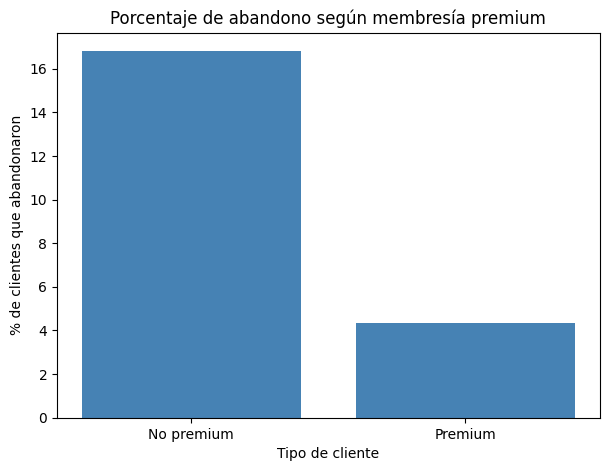

In [ ]:
# Se revisa el porcentaje de abandono se personas premium
# Porcentaje de abandono según membresía premium
tasa_abandono = df.groupby('miembro_premium')['abandono'].mean() * 100
print(tasa_abandono.round(1))

plt.figure(figsize=(7, 5))
plt.bar(['No premium', 'Premium'], tasa_abandono.values, color='steelblue')
plt.title('Porcentaje de abandono según membresía premium')
plt.xlabel('Tipo de cliente')
plt.ylabel('% de clientes que abandonaron')
plt.show()

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo, sin embargo V de Cramér está incompleto: faltan `abandono` vs. `tipo_dispositivo` y `abandono` vs. `region`
</div>

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — Las visitas podrían conectar la publicidad dirigida con las compras

**Evidencia visual:**   Scatterplots de visitas_mes vs. gasto_publicidad_dirigida y compras_mes vs. visitas_mes.

**Evidencia numérica:** Gasto-visitas: Pearson = 0.58. Visitas-compras: Pearson = 0.35. Gasto-compras: Pearson = 0.21.

**Interpretación**  Los clientes con mayor gasto publicitario tienden a visitar más la plataforma, y quienes la visitan más tienden a comprar más. La asociación directa entre gasto y compras es débil. Esto es compatible con que las visitas sean una etapa intermedia entre la publicidad y la compra.

**No podemos afirmar**  Que la publicidad cause las visitas ni que las visitas causen las compras. Tampoco sabemos si el presupuesto se asigna a quienes ya visitan más la plataforma.

**Implicación de negocio**  El desempeño de la publicidad no debería valorarse solo por el tráfico asociado, porque más visitas no siempre se reflejan en más compras.


### Hallazgo 2 — Las características y la satisfacción del cliente casi no se asocian con el ingreso

**Evidencia visual:**   Heatmap de la matriz de correlación de Pearson.

**Evidencia numérica:** Correlación con ingreso_anual: visitas_mes = 0.34; gasto_publicidad_dirigida = 0.20; satisfaccion = 0.06; edad = 0.02; nivel_ingreso = 0.02.

**Interpretación**  Entre estas variables, el comportamiento en la plataforma muestra una asociación mayor con el ingreso que la edad, el nivel de ingreso o la satisfacción, aunque ninguna relación es fuerte.

**No podemos afirmar**  Que estas variables no influyan en el ingreso. La correlación mide principalmente relaciones lineales o monótonas y no descarta efectos en segmentos específicos.

**Implicación de negocio**  Con esta evidencia, la edad, el nivel de ingreso y la satisfacción no deberían usarse por sí solos para identificar a los clientes que generan más ingresos.


### Hallazgo 3 — La membresía premium tiene una asociación muy débil con el ingreso

**Evidencia visual:**   No aplica.

**Evidencia numérica:** Correlación punto-biserial: r = 0.093; p < 0.001.

**Interpretación**  Los miembros premium tienden a generar ingresos ligeramente mayores. La relación es estadísticamente significativa, pero su magnitud es baja.

**No podemos afirmar**  Que la membresía aumente el ingreso. Es posible que los clientes con mayor disposición de compra sean quienes eligen suscribirse.

**Implicación de negocio**  Con la evidencia disponible, la membresía premium no debería considerarse por sí sola una palanca principal para aumentar el ingreso.


#### Hallazgo 4 — Los clientes premium presentan un abandono mucho menor

**Evidencia visual:**   Gráfico de barras del porcentaje de abandono según miembro_premium.

**Evidencia numérica:** V de Cramér = 0.120; p < 0.001. Abandono: premium = 4.4 % (91 de 2,089); no premium = 16.8 % (2,170 de 12,911).

**Interpretación**  Los clientes premium abandonan la plataforma en una proporción mucho menor que los no premium. Aunque la asociación es débil según V de Cramér, la diferencia entre ambos grupos es de 12.4 puntos porcentuales.

**No podemos afirmar**  Que la membresía premium reduzca el abandono. Es posible que los clientes con mayor intención de permanecer sean quienes eligen suscribirse. Tampoco conocemos el momento en que adquirieron la membresía ni si la tenían antes de abandonar.

**Implicación de negocio**  La membresía premium no se asocia de forma importante con el ingreso, pero sí con una menor proporción de abandono. Por eso, su valor para el negocio podría estar más relacionado con la retención que con el ingreso anual.


#### Hallazgo 5 — La relación entre compras e ingreso es redundante

**Evidencia visual:**   Heatmap y scatterplot de compras_mes vs. ingreso_anual.

**Evidencia numérica:** Pearson = 0.97; Spearman = 0.97.

**Interpretación**  La correlación es extremadamente alta porque ambas variables miden, en gran parte, el mismo comportamiento: el ingreso se deriva de las compras realizadas por el cliente.

**No podemos afirmar**  Que compras_mes explique de forma independiente ingreso_anual, ni que el coeficiente de 0.97 mida el efecto de aumentar las compras.

**Implicación de negocio**  compras_mes no debería usarse como factor explicativo independiente del ingreso para tomar decisiones.


<div class="alert alert-block alert-w">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

os hallazgos tienen evidencia y cautela causal
</div>

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- El análisis es correlacional, no causal: los resultados muestran asociaciones, no relaciones de causa y efecto.

- Existen variables no controladas que podrían influir en los resultados, como la antigüedad del cliente, su interés previo de compra, el valor promedio de sus compras y las promociones recibidas.
  
- Existen posibles efectos de segmentación no explorados, por ejemplo, entre clientes con y sin compras, o según región y tipo de dispositivo.

- No se conocen los criterios de asignación del gasto publicitario ni el momento en que los clientes adquirieron la membresía premium.

- Compras_mes e ingreso_anual son variables redundantes, lo que limita la interpretación de su correlación.

- Al menos el 25 % de los clientes registra ingreso_anual = 0, lo que puede influir en las correlaciones.

- Los clientes premium representan el 13.9 % de la muestra (2,089 de 15,000), por lo que los grupos comparados no están equilibrados.

- Pocos clientes registran valores extremos de compras, y el grupo de 61 a 75 años es reducido (462 clientes), lo que limita las conclusiones sobre esos segmentos.

### **Próximos pasos**

**Probar segmentación adicional**

- Segmentar a los clientes por comportamiento de compra, membresía premium, región y tipo de dispositivo para comparar su ingreso anual y abandono.
  
- Repetir las correlaciones solo con los clientes que realizaron compras.

**Realizar análisis por cohortes**
- Agrupar a los clientes según su mes de registro o de adquisición de la membresía premium para comparar su retención e ingresos a lo largo del tiempo.

- Podría hacerse un análisis por cohortes, lo que requeriría las fechas de registro o de membresía, que este dataset no incluye.


### **README**
# Análisis NovaRetail+

Análisis correlacional y exploratorio del comportamiento de 15,000 clientes de NovaRetail+, una plataforma de comercio electrónico en Latinoamérica.

🎯 **Objetivo**

Identificar qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado.

🛠️ **Datos y métodos**

- **Dataset:** 15,000 registros y 12 columnas, sin valores nulos.
- **Métodos:** Pearson, Spearman, punto-biserial y V de Cramér.
- **Herramientas:** Python, pandas, NumPy, Matplotlib, Seaborn y SciPy.

⚠️ **Calidad de los datos**

- **Tipos de datos:** las columnas están correctamente tipificadas y no requirieron cambios.
- **Valores atípicos:** se identificaron mediante diagramas de caja y se conservaron, porque no se encontraron errores evidentes.
- **Prueba de sensibilidad:** al retirar 214 registros (1.43 %), las correlaciones cambiaron como máximo 0.015 y las conclusiones se mantuvieron.

🔍 **Principales hallazgos**

- **Publicidad, visitas y compras:** el gasto publicitario se asocia más con las visitas (0.58) que con las compras (0.21). Las visitas podrían ser una etapa intermedia hacia la compra.
- **Factores asociados con el ingreso:** visitas (0.34) y gasto publicitario (0.20) muestran asociaciones débiles. Satisfacción, edad y nivel de ingreso casi no se asocian con el ingreso.
- **Membresía premium e ingreso:** la asociación es positiva, pero muy débil (r = 0.093).
- **Membresía premium y abandono:** el abandono es de 4.4 % en clientes premium y de 16.8 % en no premium (V = 0.120).
- **Compras e ingreso:** la correlación de 0.97 refleja una redundancia entre ambas variables, no un factor independiente.

💡 **Recomendaciones**

- **Evaluar la publicidad por etapas:** analizar su relación con las visitas y con la conversión en compras.
- **Revisar el valor del programa premium:** considerar su posible relación con la retención, además del ingreso.
- **Confirmar los resultados:** usar datos históricos y pruebas controladas antes de tomar decisiones.

📌 **Nota**

Este análisis identifica asociaciones, no relaciones de causa y efecto.=